# Isotonic Calibration 

Ce notebook calibre tout les modèles, et affiche un certains nombres de résultats. 
L'entrainement ce fait sur tout les modèles present dans le dossiers /models, les résultats sont ensuites sauvegardés dans le dossier model_calibrated_isotonic. 

les fonctions utilisés sont présentes et commentés dans calibration_utils

In [1]:
import sys
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Force reload calibration_utils to pick up the latest version
if 'src.calibration_utils' in sys.modules:
    del sys.modules['src.calibration_utils']
if 'calibration_utils' in sys.modules:
    del sys.modules['calibration_utils']

sys.path.insert(0, './src')
from src.calibration_utils import calibrate_all_models, plot_all_calibration_comparison

In [2]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================

# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_cal = cal_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Calibration: {X_cal.shape[0]} lignes, {X_cal.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes, {X_test.shape[1]} features")

📂 Chargement des données...
✓ Données chargées:
   - Calibration: 28381 lignes, 81 features
   - Test: 28465 lignes, 81 features


In [3]:
# =============================================================================
# CELLULE 2 : CALIBRATION DE TOUS LES MODÈLES (ISOTONIC)
# =============================================================================

# Calibrer tous les modèles avec Isotonic Regression
results_df = calibrate_all_models(
    model_dir='models',
    output_dir='model_calibrated_isotonic',
    X_cal=X_cal,
    y_cal=y_cal,
    X_test=X_test,
    y_test=y_test,
    method='isotonic',  # Isotonic Regression
    pattern='*_tuned.pkl',
    save_plots=True,
    save_results_dir='results'
)

print("\n✅ Calibration Isotonic terminée!")

📂 Modèles trouvés dans 'models':
   - xgboost_tuned.pkl
   - logistic_regression_tuned.pkl
   - random_forest_tuned.pkl
   - gradient_boosting_tuned.pkl

🔄 CALIBRATION DE 4 MODÈLES
   Méthode: isotonic
   Données calibration: 28381 échantillons
   Données test: 28465 échantillons

──────────────────────────────────────────────────
📦 Modèle: xgboost
──────────────────────────────────────────────────
   ✓ Modèle chargé: models/xgboost_tuned.pkl
   🔄 Calibration avec méthode: isotonic

   📊 Métriques sur Test Set:
      Brier Score:   0.2106 → 0.2013 (↓ 0.0092)
      Log Loss:      0.6339 → 0.5894 (↓ 0.0445)
      ROC-AUC:       0.7533 → 0.7530
   ✓ Plot sauvegardé:  results/xgboost_calibrated/xgboost_calibration_curve.png
   ✓ Métriques sauvegardées: results/xgboost_calibrated/xgboost_calibrated_metrics.csv
   ✓ Résultats sauvegardés: results/xgboost_calibrated/xgboost_calibrated_results.txt
   ✓ Modèle calibré sauvegardé: model_calibrated_isotonic/xgboost_tuned_calibrated.pkl

─────────

✓ Comparaison sauvegardée:  model_calibrated_isotonic/comparison_calibration_isotonic.png


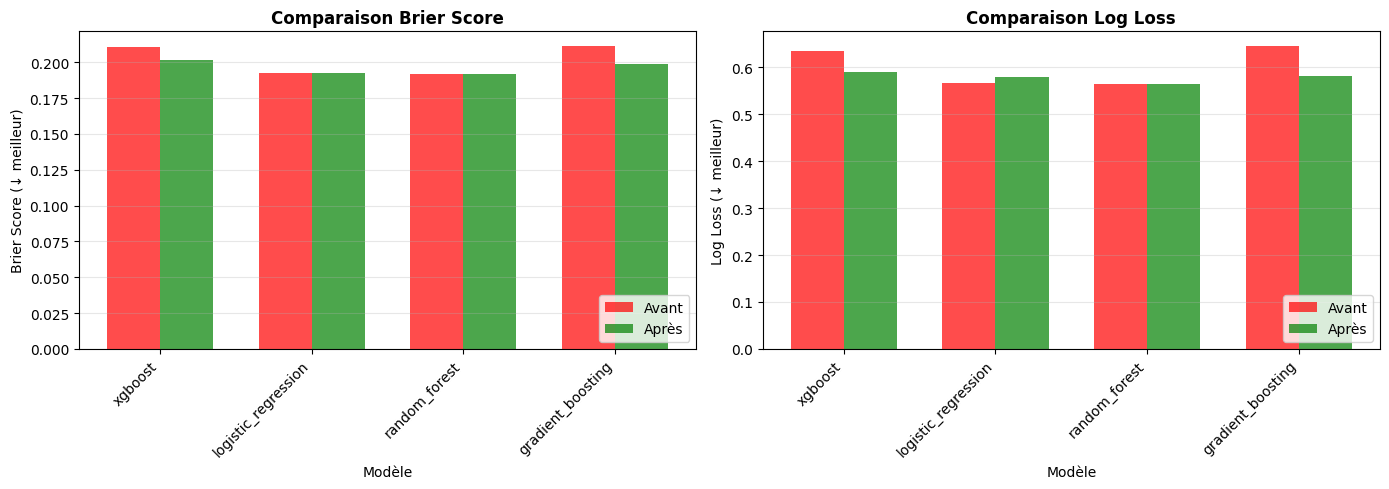


📊 Tableau récapitulatif (Isotonic):
              model  brier_before  brier_after  log_loss_before  log_loss_after  roc_auc_before  roc_auc_after  brier_improvement  log_loss_improvement
            xgboost      0.210556     0.201348         0.633890        0.589434        0.753270       0.753027           0.009209              0.044456
logistic_regression      0.192674     0.192781         0.567533        0.580383        0.776755       0.776380          -0.000106             -0.012850
      random_forest      0.191530     0.191763         0.564798        0.565245        0.779009       0.778754          -0.000233             -0.000447
  gradient_boosting      0.210959     0.198570         0.644421        0.581770        0.760236       0.759850           0.012389              0.062651


In [5]:
# =============================================================================
# CELLULE 3 : VISUALISATION COMPARATIVE
# =============================================================================

# Force reload pour s'assurer de récupérer les dernières modifications
if 'src.calibration_utils' in sys.modules:
    del sys.modules['src.calibration_utils']
if 'calibration_utils' in sys.modules:
    del sys.modules['calibration_utils']

from src.calibration_utils import plot_all_calibration_comparison

# Plot comparaison de tous les modèles
fig = plot_all_calibration_comparison(
    results_df, 
    save_path='model_calibrated_isotonic/comparison_calibration_isotonic.png'
)
plt.show()

# Afficher le tableau récapitulatif
print("\n📊 Tableau récapitulatif (Isotonic):")
print(results_df.to_string(index=False))